# GPSA Analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO


## Delta Energy Terms

### Load data

In [10]:
def load_finalenergy (mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = (f'../../data/1bf5/{mut}/rep{rep}/analysis/006.gbsa/FINAL_ENERGY.csv')
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the index of the line containing "Delta Energy Terms"
        start_idx = None
        for i, line in enumerate(lines):
            if "Delta Energy Terms" in line:
                start_idx = i + 1  # Start from the next line
                break

        if start_idx is None:
            raise ValueError("Section 'Delta Energy Terms' not found in the file")

        # Extract the lines after "Delta Energy Terms"
        data_lines = lines[start_idx:]
        data_string = ''.join(data_lines)
        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)
    return dfs


In [43]:
wt_delta_dfs = load_finalenergy('wt')
T419R_delta_dfs = load_finalenergy('T419R')

In [13]:
wt_delta_dfs[0].head()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
0,1000,0.0,0.0,0.0,-133.98,-277.39,0.0,0.0,260.99,-18.82,-411.37,242.17,-169.21
1,1001,0.0,0.0,0.0,-137.18,-297.28,-0.0,-0.0,281.92,-18.93,-434.46,262.98,-171.48
2,1002,-0.0,-0.0,-0.0,-135.61,-299.07,-0.0,0.0,282.32,-20.45,-434.68,261.87,-172.81
3,1003,0.0,0.0,0.0,-134.28,-298.42,0.0,0.0,283.22,-19.71,-432.69,263.52,-169.18
4,1004,-0.0,-0.0,0.0,-131.69,-282.88,-0.0,0.0,266.81,-19.98,-414.57,246.83,-167.74


### By replicate

Plot delta energy terms by replicate.

In [12]:
wt_delta_dfs[0].describe()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
count,1002.000000,1002.0,1002.0,1002.0,1002.000000,1002.000000,1002.0,1002.0,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000
mean,1500.500000,0.0,0.0,0.0,-147.208054,-321.256806,0.0,0.0,304.558393,-19.942605,-468.464551,284.615729,-183.848743
std,289.396786,0.0,0.0,0.0,9.438355,25.177154,0.0,0.0,23.818368,0.911887,27.355557,23.564614,9.822645
min,1000.000000,-0.0,0.0,0.0,-176.550000,-398.030000,0.0,-0.0,242.260000,-22.610000,-551.770000,222.510000,-217.090000
25%,1250.250000,0.0,0.0,0.0,-154.020000,-337.855000,0.0,0.0,288.500000,-20.540000,-486.032500,268.350000,-190.877500
50%,1500.500000,0.0,0.0,0.0,-147.720000,-318.480000,0.0,0.0,302.130000,-19.970000,-466.715000,282.260000,-184.310000
75%,1750.750000,0.0,-0.0,0.0,-140.545000,-304.205000,0.0,0.0,320.137500,-19.330000,-450.807500,299.782500,-176.625000
max,2001.000000,-0.0,0.0,0.0,-120.250000,-253.990000,0.0,-0.0,378.590000,-17.110000,-391.460000,358.500000,-156.460000


In [50]:
wt_delta_summary = []

for df in wt_delta_dfs:
    desc = df.describe()
    desc = desc.filter(items = ['mean', 'std'], axis=0)
    desc.loc['sem'] = df.sem()
    desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
    wt_delta_summary.append(desc)

T419R_delta_summary = []

for df in T419R_delta_dfs:
    desc = df.describe()
    desc = desc.filter(items = ['mean', 'std'], axis=0)
    desc.loc['sem'] = df.sem()
    desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
    T419R_delta_summary.append(desc)

In [51]:
wt_delta_summary[0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-147.208054,-321.256806,304.558393,-19.942605,-468.464551,284.615729,-183.848743
std,9.438355,25.177154,23.818368,0.911887,27.355557,23.564614,9.822645
sem,0.298169,0.795377,0.752451,0.028808,0.864195,0.744434,0.310309


In [47]:
T419R_delta_summary[0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-131.113084,-395.252854,375.156088,-17.808623,-526.366038,357.347415,-169.018503
std,10.393187,26.096295,24.419629,0.899971,26.456242,24.316758,10.072246
sem,0.328333,0.824413,0.771445,0.028431,0.835784,0.768196,0.318194


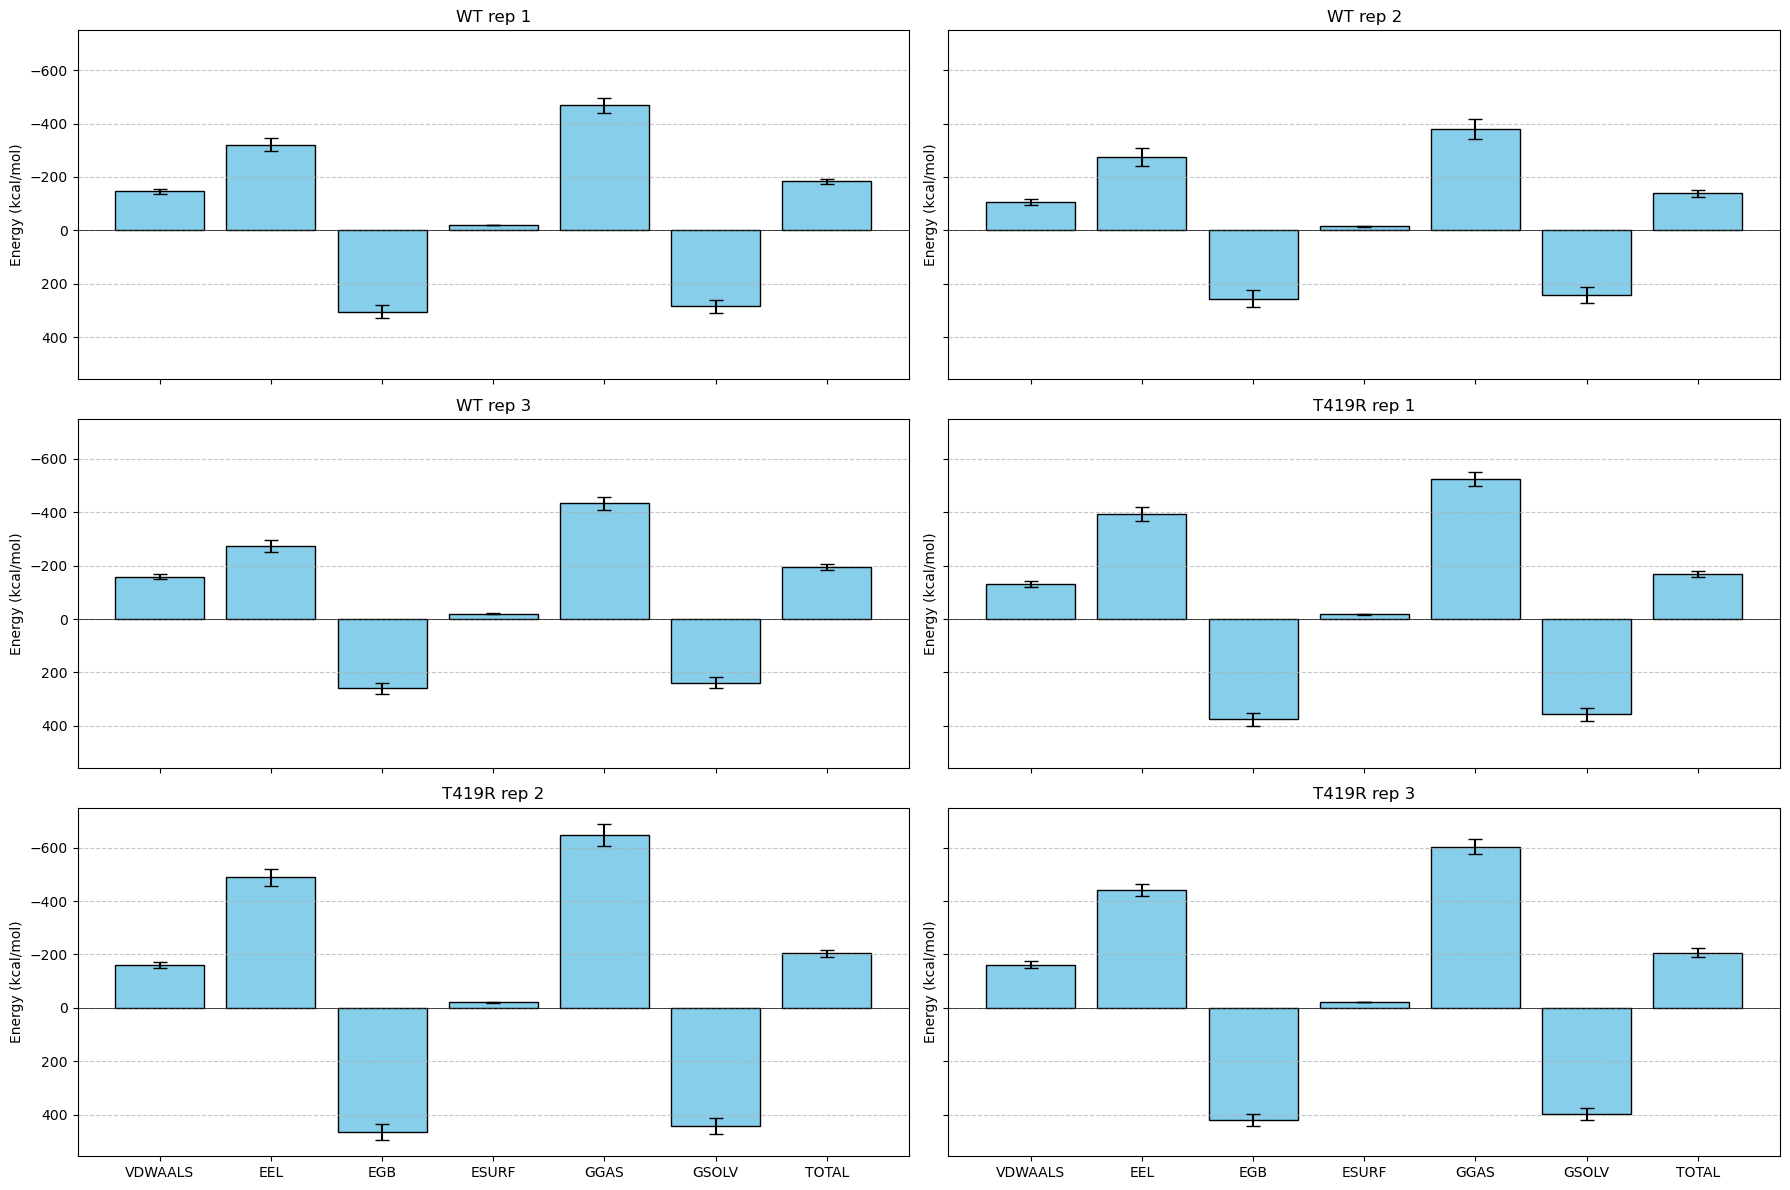

In [71]:

# Find global min and max
all_data = [
    wt_delta_summary[0].transpose().values,
    wt_delta_summary[1].transpose().values,
    wt_delta_summary[2].transpose().values,
    T419R_delta_summary[0].transpose().values,
    T419R_delta_summary[1].transpose().values,
    T419R_delta_summary[2].transpose().values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(3, 2, figsize=(18, 12), sharey=True, sharex=True)
ax1, ax2, ax3, ax4, ax5, ax6 = axes.flatten()

plots = [
    (wt_delta_summary[0].transpose(), ax1, 'WT rep 1'),
    (wt_delta_summary[1].transpose(), ax2, 'WT rep 2'),
    (wt_delta_summary[2].transpose(), ax3, 'WT rep 3'),
    (T419R_delta_summary[0].transpose(), ax4, 'T419R rep 1'),
    (T419R_delta_summary[1].transpose(), ax5, 'T419R rep 2'),
    (T419R_delta_summary[2].transpose(), ax6, 'T419R rep 3'),
]

for df, ax, title in plots:
    ax.bar(df.index, df['mean'], yerr=df['std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### By mutation (combining replicates)

In [62]:
def combine_delta(dfs):
    combined_means = []
    combined_stds = []

    # Combine for each energy term
    for col in dfs[0].columns:
        means = [df.loc['mean', col] for df in dfs]
        stds = [df.loc['std', col] for df in dfs]
        
        # Simple mean 
        combined_mean = np.mean(means)
        
        # Pooled variance and combined std
        variances = [s**2 for s in stds]
        pooled_variance = np.mean(variances)  # Since n_frames is the same, (n-1) terms cancel out
        combined_std = np.sqrt(pooled_variance)
        
        combined_means.append(combined_mean)
        combined_stds.append(combined_std)

    combined_df = pd.DataFrame({
        col: [combined_means[i], combined_stds[i]] for i, col in enumerate(wt_delta_summary[0].columns)
    }, index=['mean', 'std'])
    return combined_df


In [63]:
wt_combined_df = combine_delta(wt_delta_summary)
T419R_combined_df = combine_delta(T419R_delta_summary)

In [64]:
wt_combined_df 

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-137.768796,-289.567532,273.126104,-18.365023,-427.336244,254.760951,-172.575176
std,9.984252,27.278466,25.747698,1.298792,30.623010,25.194886,11.030096


In [61]:
T419R_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-150.892325,-441.685795,419.739182,-20.224188,-592.578177,399.514867,-193.063117
std,12.571365,27.823674,26.355668,1.487646,32.843131,25.861099,13.792357


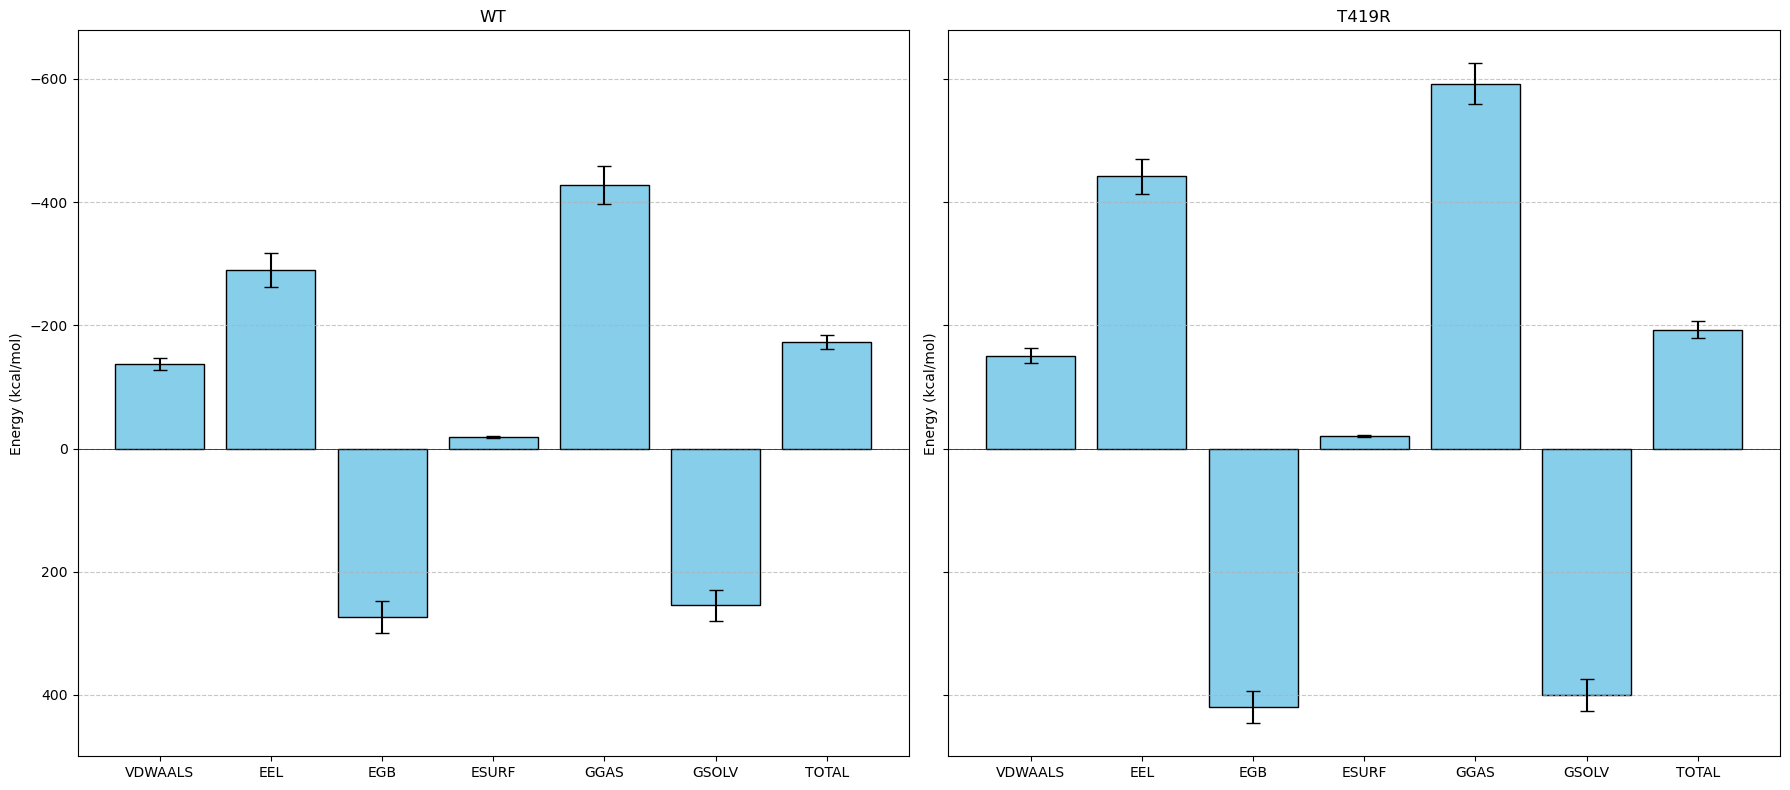

In [67]:

# Find global min and max
all_data = [
    wt_combined_df.transpose().values,
    T419R_combined_df.transpose().values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2 = axes.flatten()

plots = [
    (wt_combined_df.transpose(), ax1, 'WT'),
    (T419R_combined_df.transpose(), ax2, 'T419R'),
]

for df, ax, title in plots:
    ax.bar(df.index, df['mean'], yerr=df['std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Residue decomposition

### Load data

In [91]:
def load_decompenergy(mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = f'../../data/1bf5/{mut}/rep{rep}/analysis/006.gbsa/FINAL_ENERGY_DECOMP.csv'
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the start and end indices for the section
        start_idx = None
        end_idx = None
        for i, line in enumerate(lines):
            line_clean = line.strip()
            if "DELTAS:" in line_clean:
                start_idx = i + 2  # Skip "DELTAS:" and "Total Decomposition Contribution (TDC)"
                continue
            if start_idx is not None and "Sidechain Decomposition Contribution" in line_clean:
                end_idx = i  
                break

        # Extract the lines between start_idx and end_idx
        data_lines = lines[start_idx:end_idx]
        data_string = ''.join(data_lines)

        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)

    return dfs

In [92]:
wt_decomp_dfs = load_decompenergy('wt')
T419R_decomp_dfs = load_decompenergy('T419R')

In [93]:
wt_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,L:A:MET:190,0.0,-0.36,-0.97,0.92,-0.02,-0.44
1,1000,L:A:PRO:191,0.0,-0.29,-0.50,0.48,-0.02,-0.32
2,1000,L:A:THR:192,0.0,-1.20,-0.89,0.56,-0.52,-2.05
3,1000,L:A:HIE:193,0.0,-0.26,-0.82,0.82,0.00,-0.27
4,1000,L:A:VAL:199,0.0,-0.04,0.04,-0.03,0.00,-0.04


In [94]:
T419R_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,L:A:MET:190,0.0,-0.11,-0.12,0.12,0.00,-0.11
1,1000,L:A:PRO:191,0.0,-0.07,-0.34,0.33,0.00,-0.08
2,1000,L:A:THR:192,0.0,-0.49,-0.73,0.70,-0.17,-0.70
3,1000,L:A:HIE:193,0.0,-0.26,-1.16,1.11,-0.10,-0.41
4,1000,L:A:LYS:201,0.0,-0.90,-37.32,36.51,-0.30,-2.02


In [97]:
for df in (wt_decomp_dfs + T419R_decomp_dfs):
    split_cols = df["Residue"].str.split(":", expand=True)
    df["compound"] = split_cols[0]
    df["chain"] = split_cols[1]
    df["resnm"] = split_cols[2]
    df["resid"] = split_cols[3]


In [98]:
wt_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL,compound,chain,resnm,resid
0,1000,L:A:MET:190,0.0,-0.36,-0.97,0.92,-0.02,-0.44,L,A,MET,190
1,1000,L:A:PRO:191,0.0,-0.29,-0.50,0.48,-0.02,-0.32,L,A,PRO,191
2,1000,L:A:THR:192,0.0,-1.20,-0.89,0.56,-0.52,-2.05,L,A,THR,192
3,1000,L:A:HIE:193,0.0,-0.26,-0.82,0.82,0.00,-0.27,L,A,HIE,193
4,1000,L:A:VAL:199,0.0,-0.04,0.04,-0.03,0.00,-0.04,L,A,VAL,199


In [123]:
def decomp_summary (dfs):
    dfs_decomp_summary = []

    # Energy columns to summarize
    energy_columns = [
        'Internal', 'van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]

    for df in dfs:
        # Group by residue identifiers
        grouped = df.groupby(['Residue', 'compound', 'chain', 'resnm', 'resid'])
        
        # Compute mean, std, and sem for energy columns
        desc = pd.concat([
            grouped[energy_columns].mean().rename(columns=lambda x: f'{x}_mean'),
            grouped[energy_columns].std().rename(columns=lambda x: f'{x}_std'),
        ], axis=1)
        
        # Reset index to make Residue, compound, chain, resnm, resid regular columns
        desc = desc.reset_index()
        
        # Append to summary list
        dfs_decomp_summary.append(desc)
    return dfs_decomp_summary

In [124]:
wt_decomp_summary = decomp_summary(wt_decomp_dfs)
T419R_decomp_summary = decomp_summary(T419R_decomp_dfs)

In [125]:
wt_decomp_summary[0].head()

,Residue,compound,chain,resnm,resid,Internal_mean,van der Waals_mean,Electrostatic_mean,Polar Solvation_mean,Non-Polar Solv._mean,TOTAL_mean,Internal_std,van der Waals_std,Electrostatic_std,Polar Solvation_std,Non-Polar Solv._std,TOTAL_std
0,L:A:ARG:243,L,A,ARG,243,0.0,-0.812884,-33.997984,32.926407,-0.118253,-2.002874,0.0,0.551134,0.639254,0.540212,0.030703,0.507411
1,L:A:ARG:283,L,A,ARG,283,0.0,-0.357176,-28.120120,27.481786,-0.140250,-1.135699,0.0,0.632486,4.142819,3.857355,0.187710,0.905507
2,L:A:ASN:285,L,A,ASN,285,0.0,-1.392754,-0.532275,0.499192,-0.204701,-1.630489,0.0,1.021933,1.165361,1.007648,0.147839,1.219752
3,L:A:ASN:325,L,A,ASN,325,0.0,-2.883244,-1.444401,1.438104,-0.609890,-3.499361,0.0,0.784771,0.292259,0.247205,0.060625,0.747075
4,L:A:GLN:205,L,A,GLN,205,0.0,-1.156737,-1.226048,1.056826,-0.306437,-1.632345,0.0,0.731263,0.387292,0.272394,0.079696,0.696818


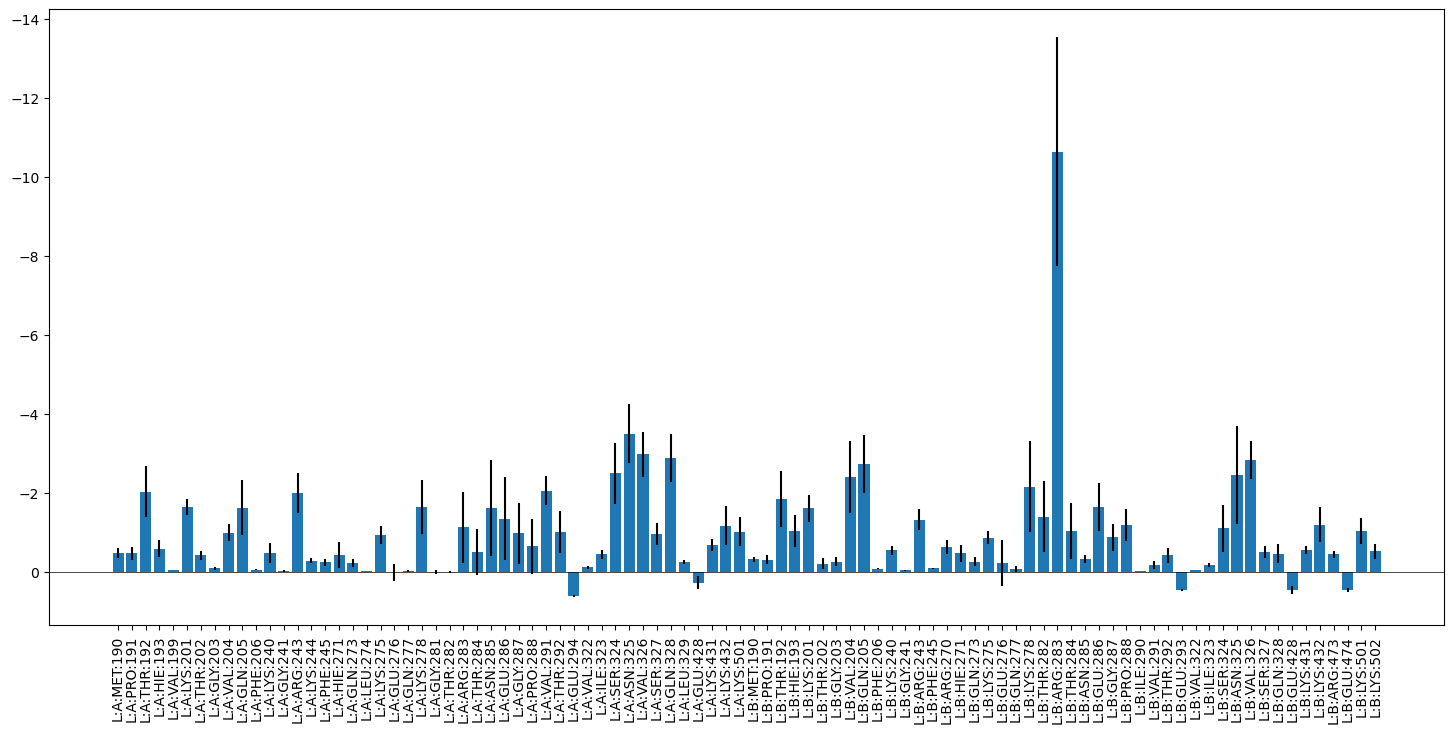

In [127]:
df = wt_decomp_summary[0][wt_decomp_summary[0]["compound"] == "L"].sort_values(by=["chain", "resid"], ascending=True)
plt.figure(figsize=(18, 8))
plt.bar(df['Residue'], df['TOTAL_mean'], yerr=df['TOTAL_std'])
plt.gca().invert_yaxis()
plt.axhline(0, color='black', linewidth=0.5)
plt.xticks(rotation=90)
plt.show()

In [130]:
def combine_decomp(dfs):
    combined_means = []
    combined_stds = []

    # Combine for each energy term
    for col in dfs[0].columns:
        
        # Simple mean 
        combined_mean = np.mean(df["TOTAL_mean"])
        
        stds = df["TOTAL_std"]
        # Pooled variance and combined std
        variances = [s**2 for s in stds]
        pooled_variance = np.mean(variances)  # Since n_frames is the same, (n-1) terms cancel out
        combined_std = np.sqrt(pooled_variance)
        
        combined_means.append(combined_mean)
        combined_stds.append(combined_std)

    combined_df = pd.DataFrame({
        col: [combined_means[i], combined_stds[i]] for i, col in enumerate(wt_delta_summary[0].columns)
    }, index=['mean', 'std'])
    return combined_df

In [131]:
wt_decomp_combined_df = combine_decomp(wt_decomp_summary)

In [132]:
wt_decomp_combined_df.head()

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-0.927402,-0.927402,-0.927402,-0.927402,-0.927402,-0.927402,-0.927402
std,0.539557,0.539557,0.539557,0.539557,0.539557,0.539557,0.539557
